In [1]:
import requests

In [2]:
c = requests.request(method="GET", url="https://data.daniel-williams.co.uk/summit/summit")
summits = c.json()
summits = [summit for summit in summits if "munro" in summit['types']]

In [3]:
import srtm
geo_elevation_data = srtm.get_data()

In [4]:
import matplotlib.pyplot as plt

In [5]:
from scipy.ndimage.filters import gaussian_filter

In [6]:
import numpy as np
from scipy import interpolate

In [7]:
import matplotlib.patheffects as pe

In [8]:
def plot_munro(munro, ax=None):
    center = munro['lat'], munro['lon']
    name = munro['name']
    data = np.zeros((200,200))
    
    lons = np.linspace(center[0]-0.025, center[0]+0.025, 200)
    lats = np.linspace(center[1]-0.025, center[1]+0.025, 200)

    aa, bb = np.meshgrid(lons, lats)
    
    levels = np.arange(0, 1500, 100)
    
    for i in range(len(lons)):
        for j in range(len(lats)):
            data[i, j] = geo_elevation_data.get_elevation(aa[i, j], bb[i, j], approximate=False)
    
    nans = np.isnan(data)
    x = lambda z: z.nonzero()[0]
    
    f = interpolate.interp2d(aa[~nans], bb[~nans], data[~nans], kind='cubic')
    
    data = f(aa, bb)
    
    #data[nans] = np.interp(x(nans), x(~nans), data[~nans])
    
    blurred = gaussian_filter(data.T, sigma=2.5)
    
    if not ax:
        f, ax = plt.subplots(dpi=300)
        
    ax.contourf(lats, lons, blurred, levels=levels, alpha=1, cmap="Greys")#, cmap="gist_earth")
    
    ax.text(x= 0.97, y =0.8, s=name, 
            horizontalalignment="right", 
            color="black",
            fontdict={'fontname':'Source Code Pro', 'fontweight': 'bold', "fontsize": 7},
            path_effects=[pe.Stroke(linewidth=2, foreground='w'), pe.Normal()],
            transform=axis.transAxes)
    
    ax.text(x= 0.99, y =0.7, s=f"{munro['height']} m", 
            horizontalalignment="right", 
            fontdict={'fontname':'Source Code Pro', "fontsize": 6},
            color="white",
            transform=axis.transAxes)
    
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_frame_on(False)
    ax.set_aspect(1)
    return ax

In [9]:
summits = c.json()
summits = [summit for summit in summits if "munro" in summit['types']]
summits.sort(reverse=True, key=lambda x: x['height'])

Exception: Cannot retrieve http://dds.cr.usgs.gov/srtm/version2_1/SRTM3/Eurasia/N56W006.hgt.zip

findfont: Font family ["'URW Bookman L'"] not found. Falling back to DejaVu Sans.


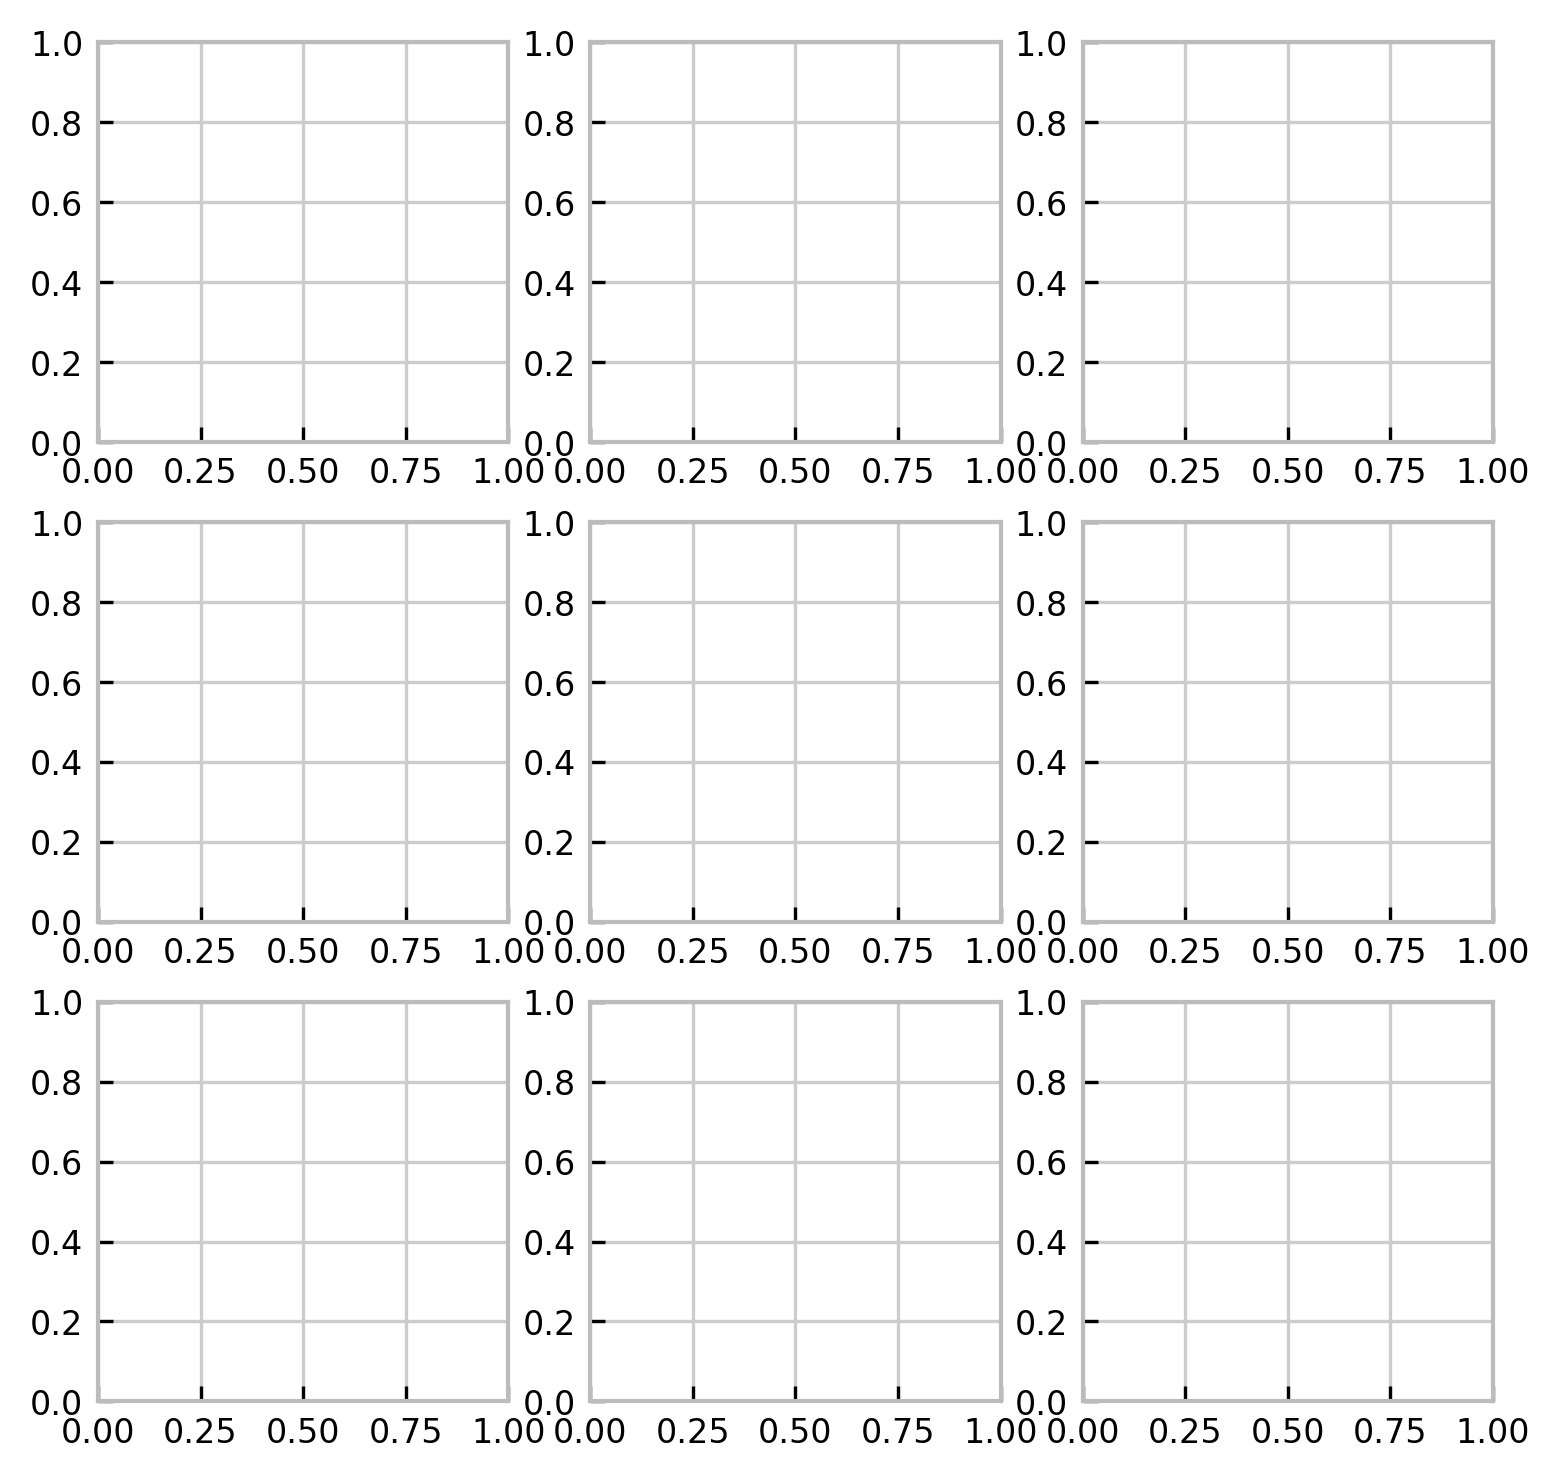

In [10]:
f, ax = plt.subplots(3,3, dpi=300, figsize=(6,6));
for summit, axis in zip(summits[:9], ax.flatten()):
    plot_munro(summit, axis);

In [190]:
lats[-1] - lats[0]

0.05000000000000071

In [189]:
lons[-1] - lons[0]

0.04999999999999716

In [109]:
center = 56.50237, -4.72301 #56.52577, -4.41735# dorain 56.50237, -4.72301 # lui 56.39704, -4.8111

In [117]:
for i in range(len(lons)):
    for j in range(len(lats)):
        data[i, j] = geo_elevation_data.get_elevation(aa[i, j], bb[i, j], approximate=True)

In [118]:
#data[data<500] = np.nan

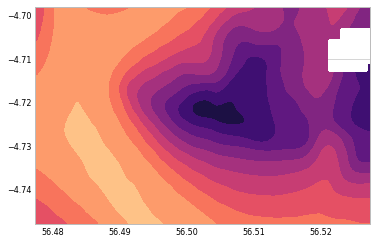

In [122]:
plt.contourf(lons, lats, blurred, levels=levels,)# cmap="gist_earth")

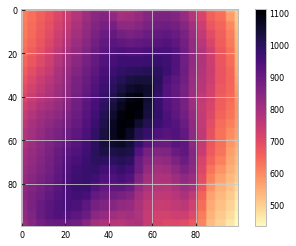

In [15]:
plt.imshow(data)
plt.colorbar()